In [35]:
# Importing Libraries
import seaborn as sns
import ast
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt 

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [2]:
df

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785736,Software Engineer,DevOps Engineer,Singapura,melalui Trabajo.org,Pekerjaan tetap,False,Singapore,2023-03-13 06:16:16,False,False,Singapore,NaN,NaN,NaN,CAREERSTAR INTERNATIONAL PTE. LTD.,"[bash, python, perl, linux, unix, kubernetes, ...","{'os': ['linux', 'unix'], 'other': ['kubernete..."
785737,Data Analyst,CRM Data Analyst,"Bad Rodach, Jerman",melalui BeBee Deutschland,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,HABA FAMILYGROUP,"[sas, sas, sql, excel]","{'analyst_tools': ['sas', 'excel'], 'programmi..."
785738,Business Analyst,Commercial Analyst - Start Now,Malaysia,melalui Ricebowl,Pekerjaan tetap,False,Malaysia,2023-03-12 06:32:36,False,False,Malaysia,NaN,NaN,NaN,Lendlease Corporation,"[powerpoint, excel]","{'analyst_tools': ['powerpoint', 'excel']}"
785739,Data Engineer,"Principal Associate, Data Engineer (Remote-Eli...","Newark, New Jersey, Amerika Serikat",melalui Recruit.net,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:15,False,False,Sudan,NaN,NaN,NaN,Capital One,"[python, go, nosql, sql, mongo, shell, mysql, ...","{'cloud': ['aws', 'snowflake', 'azure', 'redsh..."


# What are the most demanded skills for the top 3 most popular data roles?

### Methodology:
1) Clean-up skill column
2) Calculate skill count based on `job_title_short`
3) Calculate skill percentage
4) Plot final findings

In [4]:
df_US = df[df["job_country"] == "United States"].copy()

In [5]:
df_skills = df_US.explode("job_skills")

df_skills[["job_title", "job_skills"]] # from exploded df_US show job_title and job_skills columns 

,job_title,job_skills
0,Senior Clinical Data Engineer / Principal Clin...,NaN
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,python
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,c++
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,java
3,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,matlab
...,...,...
785692,Data Scientist- Hybrid Work Location,r
785703,Data Analyst - CRYPTOGRAPHY - Full-time,NaN
785705,Expert Business Data Analyst - Now Hiring,sql
785705,Expert Business Data Analyst - Now Hiring,python


In [7]:
df_skills_count = df_skills.groupby(["job_skills", "job_title_short"]).size()
df_skills_count

job_skills  job_title_short          
airflow     Business Analyst               38
            Cloud Engineer                 27
            Data Analyst                  387
            Data Engineer                4716
            Data Scientist               1166
                                         ... 
zoom        Machine Learning Engineer       5
            Senior Data Analyst            50
            Senior Data Engineer           30
            Senior Data Scientist          25
            Software Engineer              16
Length: 1870, dtype: int64

In [8]:
type(df_skills_count) # its a series and we want to transfrom to dataframe

pandas.Series

In [10]:
df_skills_count = df_skills_count.reset_index(name="skill_count") # transfrom to dataframe using reset index
df_skills_count

,job_skills,job_title_short,skill_count
0,airflow,Business Analyst,38
1,airflow,Cloud Engineer,27
2,airflow,Data Analyst,387
3,airflow,Data Engineer,4716
4,airflow,Data Scientist,1166
...,...,...,...
1865,zoom,Machine Learning Engineer,5
1866,zoom,Senior Data Analyst,50
1867,zoom,Senior Data Engineer,30
1868,zoom,Senior Data Scientist,25


In [11]:
df_skills_count.sort_values(by="skill_count", ascending=False, inplace=True) # no need to assign the dataframe to update because we use inplace

df_skills_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


In [13]:
job_titles = df_skills_count["job_title_short"].unique() # to get the unique values in job_title_short

job_titles # the output is an array

<ArrowStringArray>
[           'Data Scientist',              'Data Analyst',
             'Data Engineer',     'Senior Data Scientist',
       'Senior Data Analyst',      'Senior Data Engineer',
          'Business Analyst',         'Software Engineer',
 'Machine Learning Engineer',            'Cloud Engineer']
Length: 10, dtype: str

In [14]:
job_titles = df_skills_count["job_title_short"].unique().tolist() # convert an array to a list 

job_titles

['Data Scientist',
 'Data Analyst',
 'Data Engineer',
 'Senior Data Scientist',
 'Senior Data Analyst',
 'Senior Data Engineer',
 'Business Analyst',
 'Software Engineer',
 'Machine Learning Engineer',
 'Cloud Engineer']

In [16]:
job_titles = job_titles[:3] # slicing to get only top 3 results; note: previously we already sorted the values so in array and in list the sorted order is kept

job_titles

['Data Scientist', 'Data Analyst', 'Data Engineer']

In [17]:
job_titles = sorted(job_titles[:3]) # sorted to have in alphabetical order

job_titles

['Data Analyst', 'Data Engineer', 'Data Scientist']

In [18]:
df_skills_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


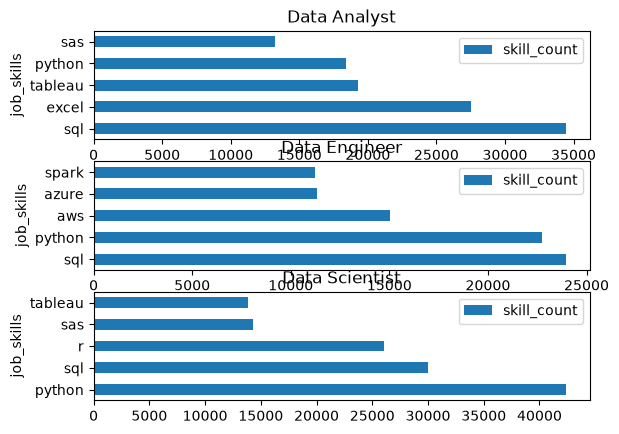

In [19]:
fig, ax = plt.subplots(len(job_titles), 1) # row is the len(job_titles) and column is 1

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count["job_title_short"] == job_title].head(5) # df[selection].head(5)
    df_plot.plot(kind="barh", x="job_skills", y="skill_count", ax=ax[i], title=job_title) # ax=ax[i] to place in subplot; title for individual plot is iteration of job_titles(iteration of job_titles is job_title we set)
    

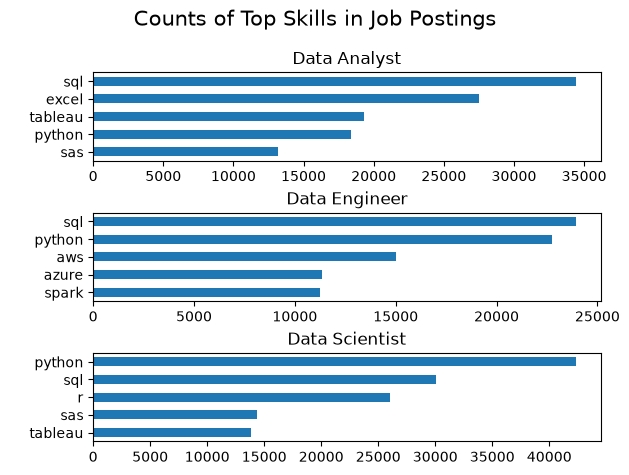

In [22]:
fig, ax = plt.subplots(len(job_titles), 1) 

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_count[df_skills_count["job_title_short"] == job_title].head(5) 
    df_plot.plot(kind="barh", x="job_skills", y="skill_count", ax=ax[i], title=job_title)
    ax[i].invert_yaxis() # to invert y axis
    ax[i].set_ylabel(" ")
    ax[i].legend().set_visible(False) # to hide legend

fig.suptitle("Counts of Top Skills in Job Postings", fontsize=15)
fig.tight_layout(h_pad=0.5) # h_pad stands for height padding. It controls the vertical spacing between vertically adjacent (stacked) subplots. we fix it tp 0.5
plt.show()

% of skill in a job posting = (skill count in job postings)/(total count of job postings)

In [28]:
df_job_title_count = df_US["job_title_short"].value_counts().reset_index(name="jobs_total") # reset_index to make a dataframe

df_job_title_count
# this dataframe shows the total counts of specific values of job_title_short

,job_title_short,jobs_total
0,Data Analyst,67816
1,Data Scientist,58830
2,Data Engineer,35080
3,Senior Data Scientist,12946
4,Senior Data Analyst,11791
5,Senior Data Engineer,9289
6,Business Analyst,7382
7,Software Engineer,1814
8,Machine Learning Engineer,921
9,Cloud Engineer,423


In [26]:
df_skills_count

,job_skills,job_title_short,skill_count
1209,python,Data Scientist,42379
1521,sql,Data Analyst,34452
1523,sql,Data Scientist,30034
455,excel,Data Analyst,27519
1243,r,Data Scientist,26022
...,...,...,...
1785,vue.js,Business Analyst,1
60,arch,Business Analyst,1
71,asana,Machine Learning Engineer,1
968,no-sql,Machine Learning Engineer,1


In [30]:
# we want to merge above two dataframes
df_skills_perc = pd.merge(df_skills_count, df_job_title_count, how="left", on="job_title_short") # merge(left df, right df); left means everything of left df is kept; column we are merging on is job_title_short
# job_title_short is the join key—the shared column pandas uses to match and align rows between both DataFrames
df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total
0,python,Data Scientist,42379,58830
1,sql,Data Analyst,34452,67816
2,sql,Data Scientist,30034,58830
3,excel,Data Analyst,27519,67816
4,r,Data Scientist,26022,58830
...,...,...,...,...
1865,vue.js,Business Analyst,1,7382
1866,arch,Business Analyst,1,7382
1867,asana,Machine Learning Engineer,1,921
1868,no-sql,Machine Learning Engineer,1,921


In [31]:
df_skills_perc["skill_percent"] = df_skills_perc["skill_count"] / df_skills_perc["jobs_total"] # we create a new column in the df_skills_perc dataframe

df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,python,Data Scientist,42379,58830,0.720364
1,sql,Data Analyst,34452,67816,0.508022
2,sql,Data Scientist,30034,58830,0.510522
3,excel,Data Analyst,27519,67816,0.405789
4,r,Data Scientist,26022,58830,0.442325
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.000135
1866,arch,Business Analyst,1,7382,0.000135
1867,asana,Machine Learning Engineer,1,921,0.001086
1868,no-sql,Machine Learning Engineer,1,921,0.001086


In [32]:
df_skills_perc["skill_percent"] = 100* df_skills_perc["skill_count"] / df_skills_perc["jobs_total"] # * 100 to be seen in the percent kinda

df_skills_perc

,job_skills,job_title_short,skill_count,jobs_total,skill_percent
0,python,Data Scientist,42379,58830,72.036376
1,sql,Data Analyst,34452,67816,50.802171
2,sql,Data Scientist,30034,58830,51.052184
3,excel,Data Analyst,27519,67816,40.578919
4,r,Data Scientist,26022,58830,44.232534
...,...,...,...,...,...
1865,vue.js,Business Analyst,1,7382,0.013546
1866,arch,Business Analyst,1,7382,0.013546
1867,asana,Machine Learning Engineer,1,921,0.108578
1868,no-sql,Machine Learning Engineer,1,921,0.108578


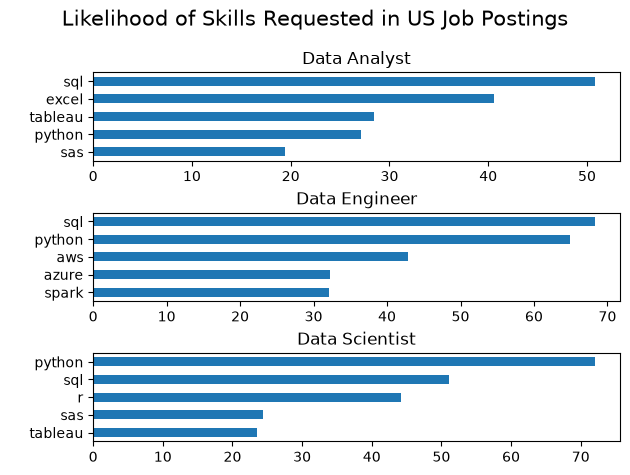

In [34]:
fig, ax = plt.subplots(len(job_titles), 1) 

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc["job_title_short"] == job_title].head(5) 
    df_plot.plot(kind="barh", x="job_skills", y="skill_percent", ax=ax[i], title=job_title)
    ax[i].invert_yaxis() # to invert y axis
    ax[i].set_ylabel(" ")
    ax[i].legend().set_visible(False) # to hide legend

fig.suptitle("Likelihood of Skills Requested in US Job Postings", fontsize=15)
fig.tight_layout(h_pad=0.5) # h_pad stands for height padding. It controls the vertical spacing between vertically adjacent (stacked) subplots. we fix it tp 0.5
plt.show()

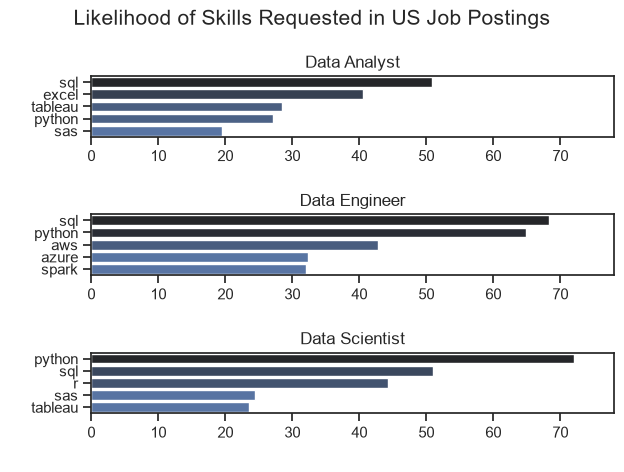

In [41]:
# use seaborn
fig, ax = plt.subplots(len(job_titles), 1) 

sns.set_theme(style="ticks")

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc["job_title_short"] == job_title].head(5) 
    #df_plot.plot(kind="barh", x="job_skills", y="skill_percent", ax=ax[i], title=job_title)

    sns.barplot(data=df_plot, x="skill_percent", y="job_skills", ax=ax[i], hue="skill_count", palette="dark:b_r")

    ax[i].set_title(job_title)
    ax[i].set_ylabel(" ")
    ax[i].set_xlabel(" ")
    ax[i].legend().set_visible(False) # to hide legend
    ax[i].set_xlim(0, 78)

fig.suptitle("Likelihood of Skills Requested in US Job Postings", fontsize=15)
fig.tight_layout(h_pad=0.5) # h_pad stands for height padding. It controls the vertical spacing between vertically adjacent (stacked) subplots. we fix it tp 0.5
plt.show()

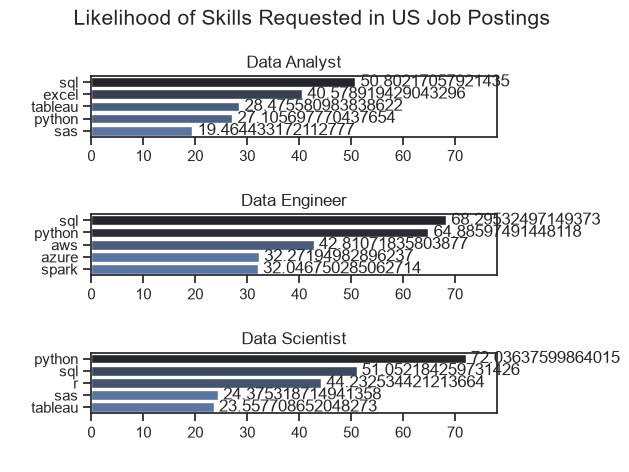

In [43]:
# use seaborn
fig, ax = plt.subplots(len(job_titles), 1) 

sns.set_theme(style="ticks")

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc["job_title_short"] == job_title].head(5) 
    #df_plot.plot(kind="barh", x="job_skills", y="skill_percent", ax=ax[i], title=job_title)

    sns.barplot(data=df_plot, x="skill_percent", y="job_skills", ax=ax[i], hue="skill_count", palette="dark:b_r")

    ax[i].set_title(job_title)
    ax[i].set_ylabel(" ")
    ax[i].set_xlabel(" ")
    ax[i].legend().set_visible(False) # to hide legend
    ax[i].set_xlim(0, 78)

    for n, v in enumerate(df_plot["skill_percent"]):
        ax[i].text(v+1, n, v, va="center") # text method on ax[i] directly, v+1= x-coord so its not so close to the bar, n = y-coord, v is the text that is going to be put; vertical alignemnt to be centered

fig.suptitle("Likelihood of Skills Requested in US Job Postings", fontsize=15)
fig.tight_layout(h_pad=0.5) # h_pad stands for height padding. It controls the vertical spacing between vertically adjacent (stacked) subplots. we fix it tp 0.5
plt.show()


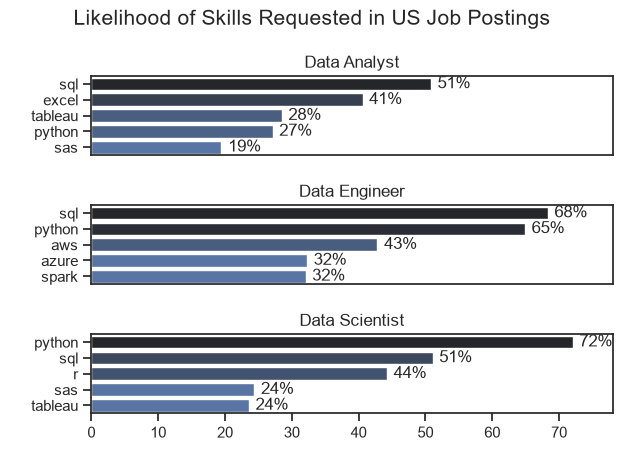

In [48]:
# the notable problem above is too much decimal places we fix by f string

# use seaborn
fig, ax = plt.subplots(len(job_titles), 1) 

sns.set_theme(style="ticks")

for i, job_title in enumerate(job_titles):
    df_plot = df_skills_perc[df_skills_perc["job_title_short"] == job_title].head(5) 
    #df_plot.plot(kind="barh", x="job_skills", y="skill_percent", ax=ax[i], title=job_title)

    sns.barplot(data=df_plot, x="skill_percent", y="job_skills", ax=ax[i], hue="skill_count", palette="dark:b_r")

    ax[i].set_title(job_title)
    ax[i].set_ylabel(" ")
    ax[i].set_xlabel(" ")
    ax[i].legend().set_visible(False) # to hide legend
    ax[i].set_xlim(0, 78)

    for n, v in enumerate(df_plot["skill_percent"]):
        ax[i].text(v+1, n, f"{v:.0f}%", va="center") # .0 decimal places; f means floating point

    if i !=len(job_titles) - 1: # != not equal to
       ax[i].set_xticks([]) # so no x axis ticks - we have the percenatge near the bars already so no need if i not equal to 2 basically; Executes its block for every subplot except the last one at the bottom. index 2 is the bottom plot

fig.suptitle("Likelihood of Skills Requested in US Job Postings", fontsize=15)
fig.tight_layout(h_pad=0.5) # h_pad stands for height padding. It controls the vertical spacing between vertically adjacent (stacked) subplots. we fix it tp 0.5
plt.show()
